# 05 — Dev Benchmark B0 / B1 / P1

**Tahap 7–8 ceklis: Implementasi metode dan dev benchmark** · README bagian 21, 27 (A1, A3), 28 (E5)

**Status: development benchmark, bukan hasil utama.** Kueri = 100 dokumen korpus acak (seed 2906); dokumen kueri dikeluarkan dari himpunan eligible. Workload final disusun dan dibekukan di Tahap 5.

**Data:** `results/raw/dev_benchmark.jsonl` dari `python -m src.benchmark.dev_benchmark` (100 kueri × 8 predikat × 27 konfigurasi = 21.600 baris).

**Implementasi:** TwoHop (Algorithm 1) dan AdaptiveL (Algorithm 2–3) mengikuti pseudocode Liu et al. (2026); deviasi dan interpretasi dicatat di `docs/paper-adaptation-notes.md`. Latency diukur dari penelusuran Python sehingga hanya sah untuk perbandingan antarmetode.

## Langkah 1: Membaca hasil benchmark

In [1]:
# Hasil dev benchmark: satu baris per kueri x predikat x konfigurasi
import pandas as pd

hasil = pd.read_json("../results/raw/dev_benchmark.jsonl", lines=True)
print("Jumlah baris:", len(hasil))
print("Predikat:", hasil["filter_id"].nunique(), "| konfigurasi:", hasil["config"].nunique(), "| kueri:", hasil["query_id"].nunique())
hasil.groupby("filter_id")["match_rate"].first().mul(100).round(3)

Jumlah baris: 21600
Predikat: 8 | konfigurasi: 27 | kueri: 100


filter_id
B2|kabupaten=Pangandaran∧alam     0.247
B2|kabupaten=Tanggamus            0.171
B3|penerbit=jawapos.com           2.079
B3|provinsi=Aceh                  1.932
B4|penerbit=detik.com             7.224
B4|provinsi=Bali                  3.467
B5|kategori=alam                 40.771
B5|temporal>=2026-07-23          12.032
Name: match_rate, dtype: float64

## Langkah 2: Recall@10 per konfigurasi dan bin

Rata-rata Recall@10 setiap konfigurasi di setiap bin match rate, ditambah biaya pencarian (median dan p95 latency, median perbandingan jarak, median evaluasi predikat) dan proporsi kueri under-filled.

In [2]:
# Recall per bin, lalu digabung dengan ringkasan biaya per konfigurasi
recall_bin = hasil.pivot_table(index="config", columns="bin", values="recall_at_10", aggfunc="mean").round(3)
recall_bin["rata2"] = recall_bin.mean(axis=1).round(3)

biaya = hasil.groupby("config").agg(
    latency_med_ms=("latency_ms", "median"),
    latency_p95_ms=("latency_ms", lambda s: s.quantile(0.95)),
    jarak_med=("distance_comparisons", "median"),
    predikat_med=("predicate_evaluations", "median"),
    underfilled=("underfilled", "mean"),
).round(2)

ringkasan = recall_bin.join(biaya).sort_values("rata2")
ringkasan

,B2,B3,B4,B5,rata2,latency_med_ms,latency_p95_ms,jarak_med,predikat_med,underfilled
config,,,,,,,,,,
method=postfilter candidate_budget=100,0.015,0.195,0.362,0.751,0.331,1.44,1.82,1937.5,100.0,0.78
method=adaptivel L=100 n_sample=64 m_max=1,0.015,0.196,0.364,0.752,0.332,1.36,1.73,1937.5,103.0,0.78
method=adaptivel L=100 n_sample=64 m_max=2,0.032,0.295,0.437,0.764,0.382,2.48,3.08,3600.0,203.0,0.71
method=adaptivel L=100 n_sample=32 m_max=2,0.035,0.326,0.491,0.770,0.406,2.41,3.09,3398.0,202.0,0.70
method=adaptivel L=100 n_sample=64 m_max=4,0.065,0.360,0.462,0.774,0.415,3.49,5.10,4955.0,354.0,0.62
method=postfilter candidate_budget=200,0.030,0.353,0.538,0.777,0.424,2.35,3.00,3259.0,200.0,0.70
method=adaptivel L=200 n_sample=64 m_max=1,0.030,0.353,0.538,0.778,0.425,2.11,2.69,3259.0,202.0,0.70
method=adaptivel L=100 n_sample=64 m_max=8,0.122,0.387,0.475,0.779,0.441,4.20,8.91,5673.0,354.0,0.57
method=adaptivel L=100 n_sample=32 m_max=4,0.068,0.446,0.549,0.776,0.460,3.46,5.02,4773.0,402.0,0.61


## Langkah 3: Sensitivitas parameter AdaptiveL (E5)

Pengaruh `L_search`, `m_max`, dan `n_sample` terhadap Recall@10 di bin paling selektif (B2) dan latency p95. `m_max = 1` berarti tanpa adaptasi; recall-nya seharusnya sama dengan PostFilter pada L yang sama (pemeriksaan kewajaran).

In [3]:
# Recall B2, recall rata-rata, latency p95, dan pengali rata-rata di B2 untuk setiap kombinasi parameter
p1 = hasil[hasil["method"] == "adaptivel"]
sens = p1.groupby(["L", "m_max", "n_sample"]).apply(
    lambda g: pd.Series({
        "recall_B2": g.loc[g["bin"] == "B2", "recall_at_10"].mean(),
        "recall_semua": g["recall_at_10"].mean(),
        "latency_p95_ms": g["latency_ms"].quantile(0.95),
        "multiplier_B2": g.loc[g["bin"] == "B2", "multiplier"].mean(),
        "sampel_tercapai": g["sample_reached"].mean(),
    }),
    include_groups=False,
).round(3)
sens

recall_B2  recall_semua  latency_p95_ms  multiplier_B2  \
L     m_max n_sample                                                           
100.0 1.0   64.0          0.015         0.331           1.725          1.000   
      2.0   32.0          0.035         0.405           3.085          2.000   
            64.0          0.032         0.382           3.083          2.000   
      4.0   32.0          0.068         0.460           5.022          3.945   
            64.0          0.065         0.415           5.102          3.940   
      8.0   32.0          0.135         0.494           8.950          7.765   
            64.0          0.122         0.441           8.915          7.540   
200.0 1.0   64.0          0.030         0.425           2.690          1.000   
      2.0   32.0          0.073         0.525           4.999          2.000   
            64.0          0.068         0.499           5.135          2.000   
      4.0   32.0          0.140         0.576           8.324          3.945   
            64.0          0.132         0.536           8.675          3.940   
      8.0   32.0          0.254         0.616          15.630          7.765   
            64.0          0.230         0.568          15.720          7.540   
400.0 1.0   64.0          0.072         0.542           4.935          1.000   
      2.0   32.0          0.148         0.629           8.867          2.000   
            64.0          0.144         0.615           9.051          2.000   
      4.0   32.0          0.274         0.684          15.037          3.945   
            64.0          0.260         0.659          15.297          3.940   
      8.0   32.0          0.454         0.739          26.718          7.765   
            64.0          0.420         0.708          26.837          7.540   

                      sampel_tercapai  
L     m_max n_sample                   
100.0 1.0   64.0                  1.0  
      2.0   32.0                  1.0  
            64.0                  1.0  
      4.0   32.0                  1.0  
            64.0                  1.0  
      8.0   32.0                  1.0  
            64.0                  1.0  
200.0 1.0   64.0                  1.0  
      2.0   32.0                  1.0  
            64.0                  1.0  
      4.0   32.0                  1.0  
            64.0                  1.0  
      8.0   32.0                  1.0  
            64.0                  1.0  
400.0 1.0   64.0                  1.0  
      2.0   32.0                  1.0  
            64.0                  1.0  
      4.0   32.0                  1.0  
            64.0                  1.0  
      8.0   32.0                  1.0  
            64.0                  1.0

## Langkah 4: Recall terhadap biaya pencarian (pratinjau analisis A1)

Setiap titik adalah satu konfigurasi di satu bin. Sumbu x = median perbandingan jarak (biaya), sumbu y = Recall@10. Konfigurasi yang lebih ke kiri atas lebih efisien.

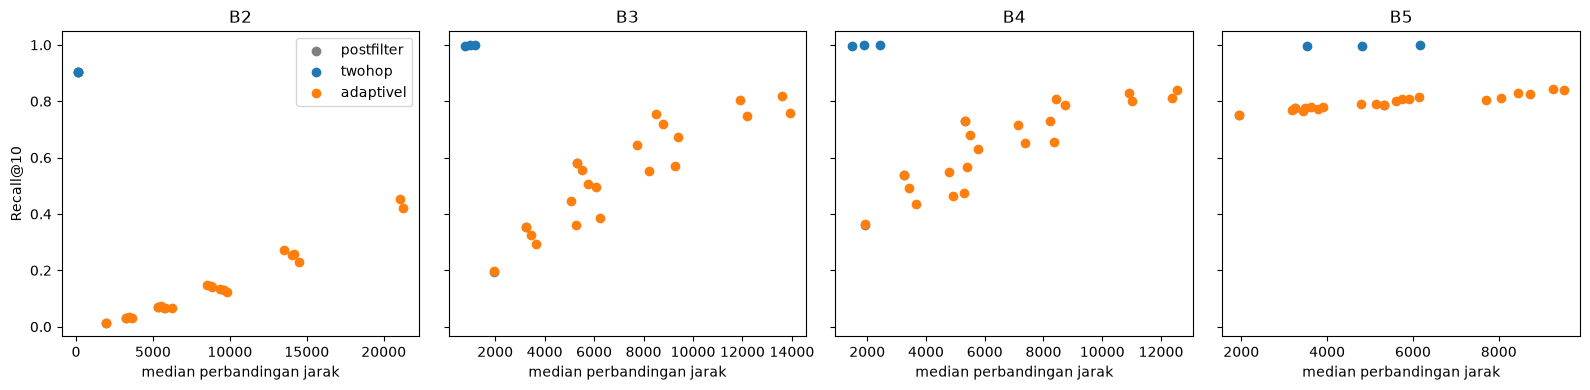

In [4]:
# Plot recall vs biaya per bin; satu warna per metode
import matplotlib.pyplot as plt

titik = hasil.groupby(["config", "method", "bin"]).agg(
    recall=("recall_at_10", "mean"), jarak=("distance_comparisons", "median")).reset_index()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, b in zip(axes, ["B2", "B3", "B4", "B5"]):
    for metode, warna in [("postfilter", "tab:gray"), ("twohop", "tab:blue"), ("adaptivel", "tab:orange")]:
        t = titik[(titik["bin"] == b) & (titik["method"] == metode)]
        ax.scatter(t["jarak"], t["recall"], label=metode, color=warna)
    ax.set_title(b)
    ax.set_xlabel("median perbandingan jarak")
axes[0].set_ylabel("Recall@10")
axes[0].legend()
plt.tight_layout()
plt.show()

## Ringkasan hasil (dijalankan di MacBook Air M4, 13 Okt 2026)

| Konfigurasi | B2 | B3 | B4 | B5 | Rata-rata | Latency median | Evaluasi predikat |
|---|---:|---:|---:|---:|---:|---:|---:|
| PostFilter, budget 100 | 0,015 | 0,195 | 0,362 | 0,751 | 0,331 | 1,4 ms | 100 |
| AdaptiveL L 100, m_max 1 | 0,015 | 0,196 | 0,364 | 0,752 | 0,332 | 1,4 ms | 103 |
| AdaptiveL L 100, n_sample 32, m_max 8 | 0,134 | 0,497 | 0,567 | 0,779 | 0,494 | 5,1 ms | 801 |
| AdaptiveL L 400, n_sample 32, m_max 8 | 0,454 | 0,818 | 0,841 | 0,843 | 0,739 | 15,2 ms | 3.200 |
| TwoHop L 100 | 0,906 | 0,997 | 0,998 | 0,995 | 0,974 | 10,2 ms | 108.187 |
| TwoHop L 400 | 0,906 | 0,998 | 1,000 | 0,998 | 0,976 | 34,6 ms | 355.896 |

Catatan reprodusibilitas: run yang sama di mesin Linux pengembang memberi recall identik kecuali selisih ±0,001 di beberapa sel (urutan skor seri pada titik berjarak sama dapat berbeda antar-CPU). Hasil resmi sebaiknya dihasilkan dan dibekukan dari satu mesin.

## Kesimpulan dan implikasi (draf)

1. **Pemeriksaan kewajaran lolos.** AdaptiveL dengan m_max = 1 memberi recall yang praktis sama dengan PostFilter pada L yang sama, sesuai harapan karena keduanya melakukan penelusuran yang sama.
2. **Penskalaan L pada AdaptiveL bekerja**, tetapi kurang kuat di korpus ini: pada L 100, recall B2 naik 0,015 → 0,134 (m_max 8); pada L 400 mencapai 0,454. n_sample 32 konsisten sedikit lebih baik daripada 64.
3. **TwoHop memberi recall tertinggi di semua bin** (≥ 0,906 di B2, ≥ 0,99 di B3–B5) dan tidak mengalami degenerasi. Paper melaporkan TwoHop runtuh pada match rate **0,01–0,1%**; rezim itu tidak diuji di sini karena syarat kecukupan ≥ 100 titik (≥ 0,155%) membuat B1 kosong.
4. **Hasil ini berlawanan dengan H1 pada rentang yang diuji.** Menurut README bagian 37, ini hasil yang sah ("TwoHop lebih baik pada corpus kecil"). Namun keunggulan AdaptiveL di paper justru berada pada rezim < 0,1% yang dikecualikan workload saat ini. **Keputusan penting untuk bimbingan:** apakah syarat kecukupan dilonggarkan (misalnya ≥ k = 10 titik, setara ≥ 0,0155%) agar rezim tersebut ikut diuji, dengan konsekuensi variasi recall yang lebih kecil.
5. **Biaya TwoHop berpindah ke evaluasi predikat** (100 ribu–350 ribu per kueri), dan pada implementasi Python ini latency median-nya ±2× AdaptiveL pada L yang sama. Karena latency Python tidak sebanding dengan C++, perbandingan biaya sebaiknya memakai jumlah perbandingan jarak dan evaluasi predikat.
6. **Usulan parameter (belum dibekukan):** kurva recall–biaya memakai L_search ∈ {100, 200, 400}; AdaptiveL n_sample = 32, m_max = 8; PostFilter candidate_budget = L_search.